In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
data_loc = '../../../data/'
fig_loc = '../figures/'

# intro

In [20]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.patches import Rectangle

from astropy.io import fits
import astropy.units as u
import astropy.constants as c

from astropy.modeling import models, fitting
fttr = fitting.LevMarLSQFitter()
gmod = models.Gaussian1D(1.,0.,1.,)

from scipy.optimize import minimize, curve_fit
from scipy.signal import find_peaks

from joblib import Parallel, delayed

from dust_3d_functions import *


In [4]:
# ednhfr = fits.open(data_loc+'maps/edenhofer_lbd.fits')[1].data #
# ednhfr_cm3 = A_to_n(ednhfr*2.8).value

ednhfr_cm3 = fits.open(data_loc+'maps/edenhofer_lbd_wrap.fits')[0].data # goes from 211 to -211 in l

In [6]:
table1 = pd.read_csv('../../../data/catalogs/mif_tab1_final.csv')
# pd.read_csv('zucker2020_clouds_within_1200pc.csv',delimiter=',')

In [ ]:
table1_2 = pd.read_csv('../../../data/catalogs/mif_tab1_longer.csv')
# table1_3 = pd.read_csv('named_co_clouds.csv') 

In [ ]:
mw_m0 = np.nansum(ednhfr_cm3,axis=0)


# fig 1: map with the clouds (all galaxy, lb and XY)

[(<matplotlib.patches.Rectangle at 0x12202f620>,),
 (<matplotlib.patches.Rectangle at 0x121beba70>,),
 (<matplotlib.patches.Rectangle at 0x12216bb90>,),
 (<matplotlib.patches.Rectangle at 0x12216bd70>,),
 (<matplotlib.patches.Rectangle at 0x12216bf80>,),
 (<matplotlib.patches.Rectangle at 0x12218c200>,),
 (<matplotlib.patches.Rectangle at 0x1212617f0>,),
 (<matplotlib.patches.Rectangle at 0x12218c650>,),
 (<matplotlib.patches.Rectangle at 0x12218c890>,),
 (<matplotlib.patches.Rectangle at 0x12218cb00>,),
 (<matplotlib.patches.Rectangle at 0x12206cce0>,),
 (<matplotlib.patches.Rectangle at 0x12218cf20>,)]

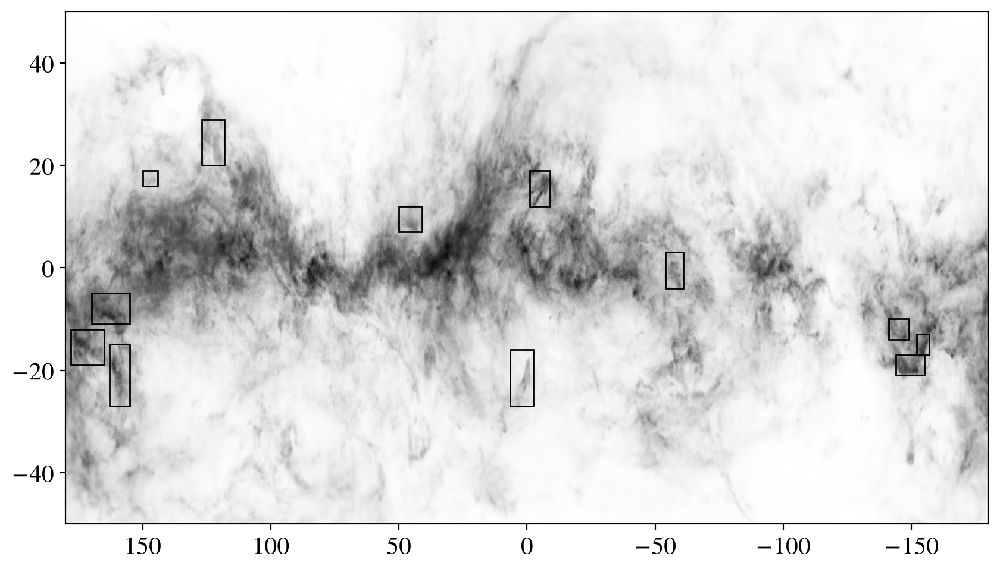

In [21]:
plt.figure(dpi=200,figsize=(10,10)),
plt.contourf(((mw_m0*u.cm**-3*u.pc).cgs/(2.2e21*u.cm**-2)).value,extent=[211,-211,-90.6,89.17],\
             cmap='binary',levels=10**np.linspace(-1.5,0.8),norm='asinh'),   #levels=np.linspace(5e1,4e3))

plt.xlim(180,-180),
plt.gca().set_aspect(2),
plt.ylim(-50,50),

[(
plt.gca().add_patch(Rectangle((lmin,bmin),lmax-lmin,bmax-bmin,fill=False)), 
)
for i in range(len(table1)) for lmin,lmax,bmin,bmax in [table1.iloc[i][1:5]]
]

<>:15: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:15: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_2793/739029212.py:15: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('Galactic Longitude [$\degree$]')
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_2793/739029212.py:16: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel('Galactic Latitude [$\degree$]')


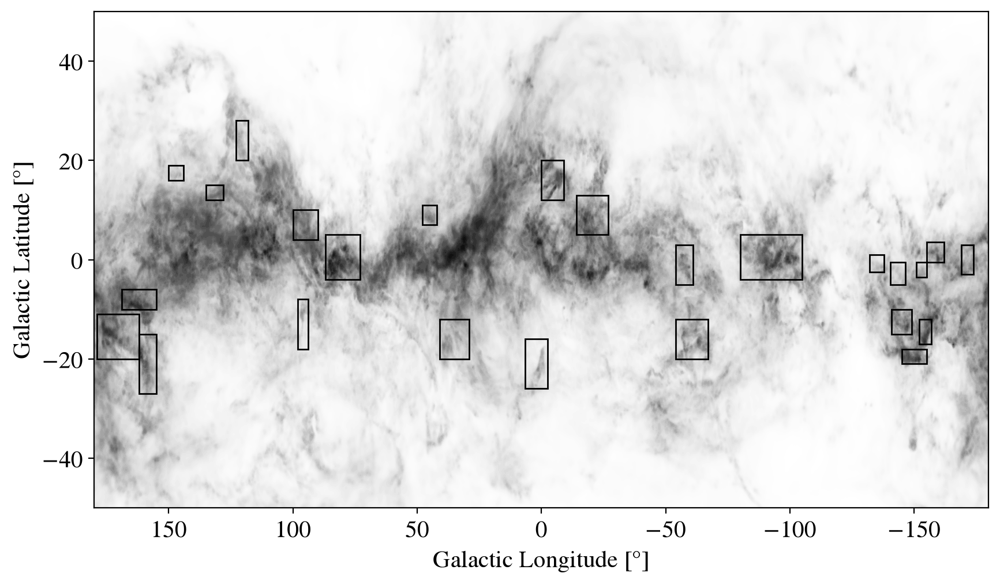

In [22]:
plt.figure(dpi=200,figsize=(10,10)),
plt.contourf(((mw_m0*u.cm**-3*u.pc).cgs/(2.2e21*u.cm**-2)).value,extent=[211,-211,-90.6,89.17],\
             cmap='binary',levels=10**np.linspace(-1.5,0.8),norm='asinh'),   #levels=np.linspace(5e1,4e3))

plt.xlim(180,-180),
plt.gca().set_aspect(2),
plt.ylim(-50,50),

[(
plt.gca().add_patch(Rectangle((lmin,bmin),lmax-lmin,bmax-bmin,fill=False)), 
)
for i in range(len(table1_2)) for lmin,lmax,bmin,bmax in [table1_2.iloc[i][1:5]]
]

plt.xlabel('Galactic Longitude [$\degree$]')
plt.ylabel('Galactic Latitude [$\degree$]')

plt.savefig(fig_loc+'fig1_catalog',bbox_inches='tight')

plt.show()


# fig 2: moment map of clouds with extinction boundaries overlaid

In [59]:
table1

,cloud,l_min(deg),l_max(deg),b_min(deg),b_max(deg),d_mean(pc)
0,California,170.0,155.0,-11.0,-5.0,450
1,Camelopardalis,150.0,144.0,16.0,19.0,213
2,Coalsack,-54.0,-61.0,-4.0,3.0,195
3,Corona,6.5,-2.5,-27.0,-16.0,156
4,Hercules,50.0,41.0,7.0,12.0,227
5,MonR2,-141.0,-149.0,-14.0,-10.0,875
6,Ophiuchus,-1.0,-9.0,12.0,19.0,150
7,Orion A,-144.0,-155.0,-21.0,-17.0,425
8,Orion B,-152.0,-157.0,-17.0,-13.0,415
9,Perseus,163.0,155.0,-27.0,-15.0,300


# RESUME HERE: 
- fit (some kind of) profile to the peak corresponding to d_mean -> use that Delta d and its multiples for subsequent analysis
- then compare Delta d length to the on-sky dimensions of the cloud -> discussion on aspect ratio / filamentaryness when deprojected 
    - for eg, imara-forbes include a cos i factor for the unknown inclination, but what happens when the cloud is dispersed along the los instead of just tilted
- then figure 3 can be the moment maps ++ 

2.0931032


<>:11: SyntaxWarning: invalid escape sequence '\o'
<>:11: SyntaxWarning: invalid escape sequence '\o'
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_2793/3483014368.py:11: SyntaxWarning: invalid escape sequence '\o'
  plt.ylabel('Mass per slice [$M_\odot\ \mathrm{pc^{-1}}$]'),


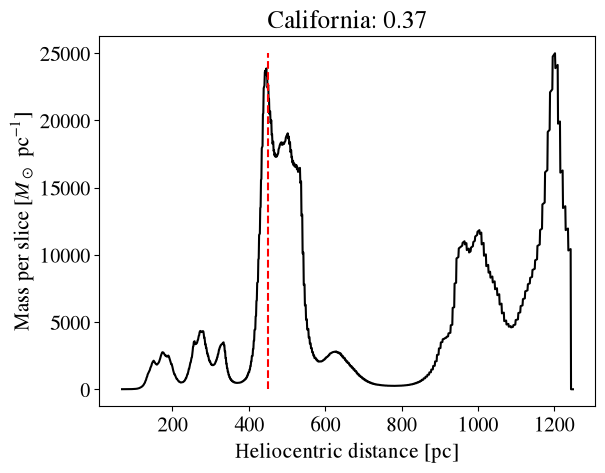

2.550017


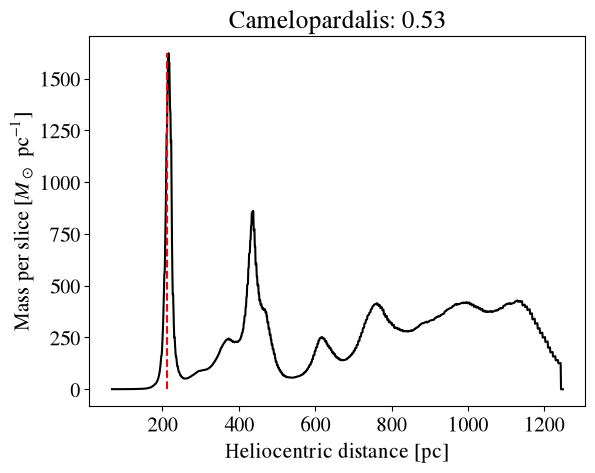

6.277087


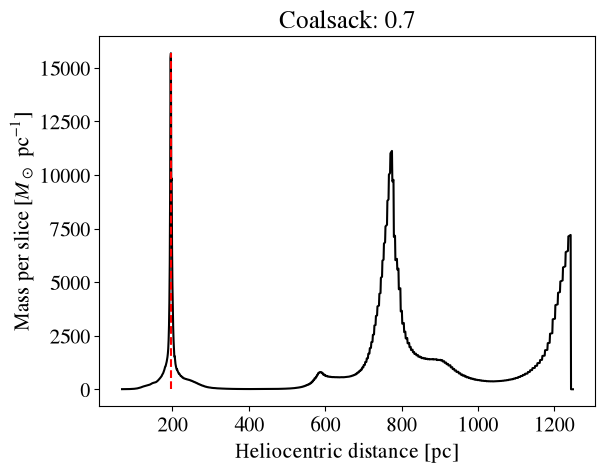

2.3219721


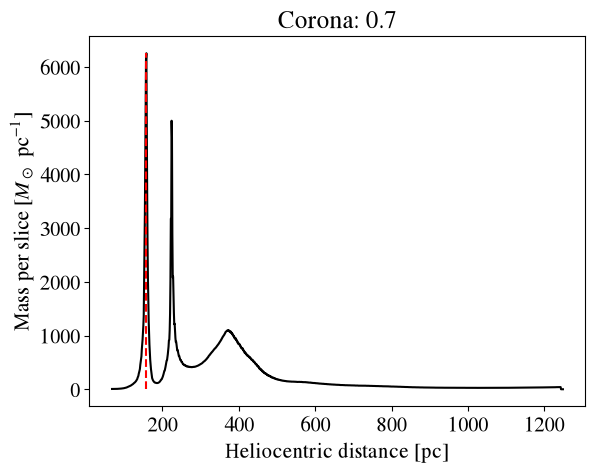

3.415196


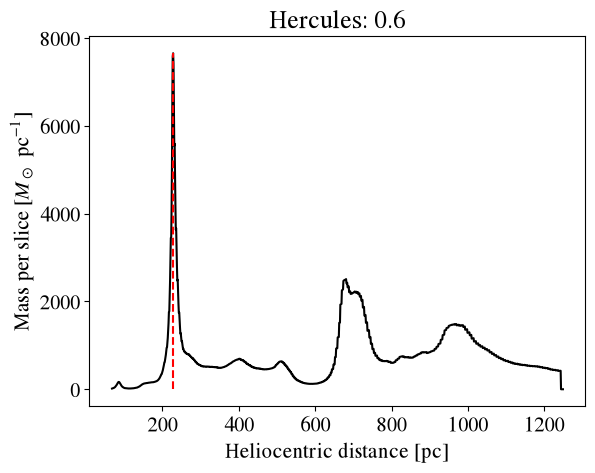

1.9015689


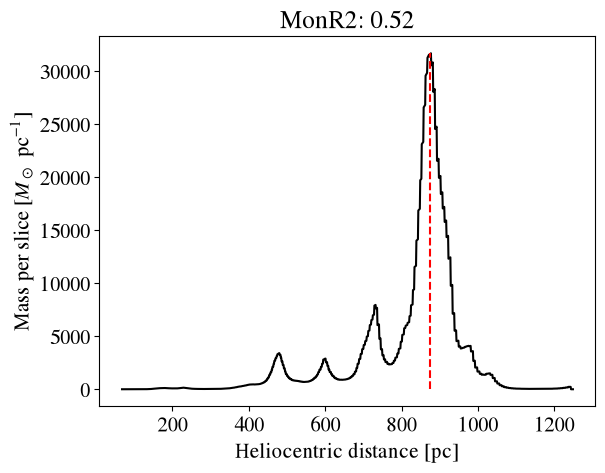

15.848083


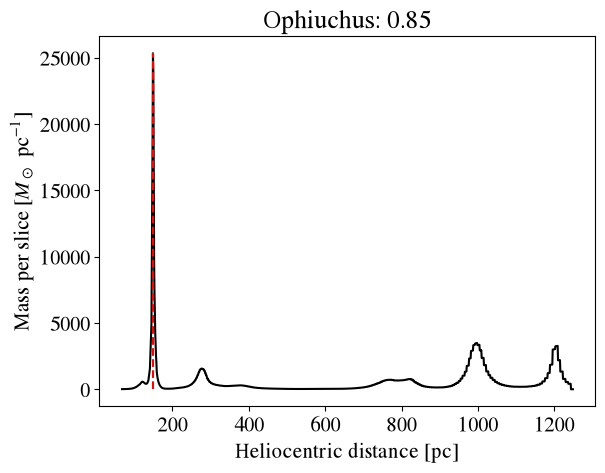

4.9367285


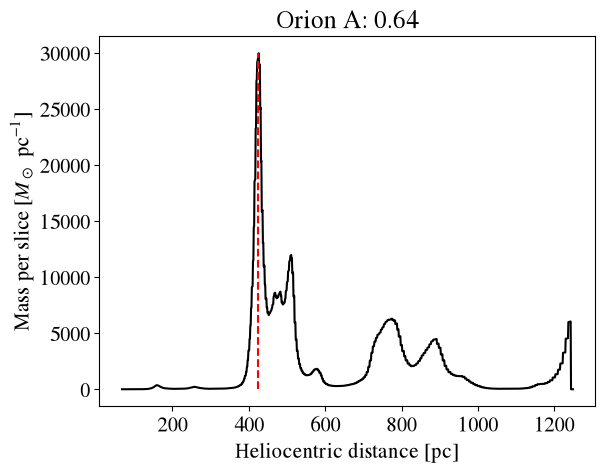

6.8076887


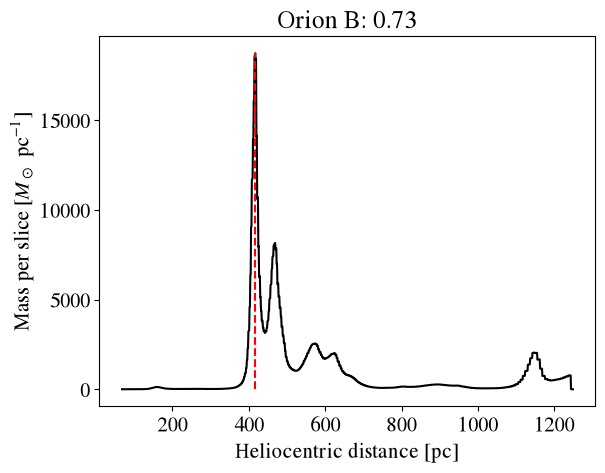

3.968299


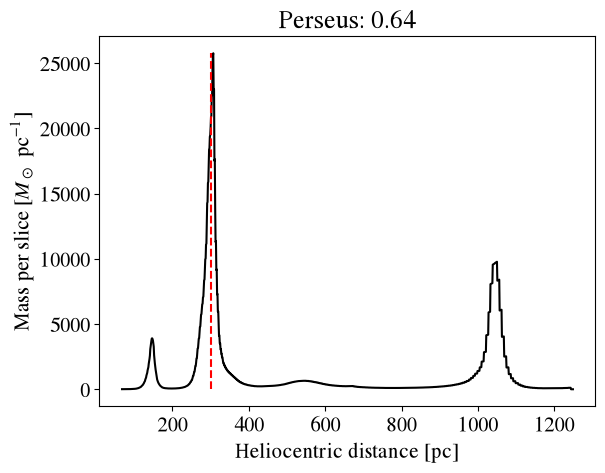

2.772025


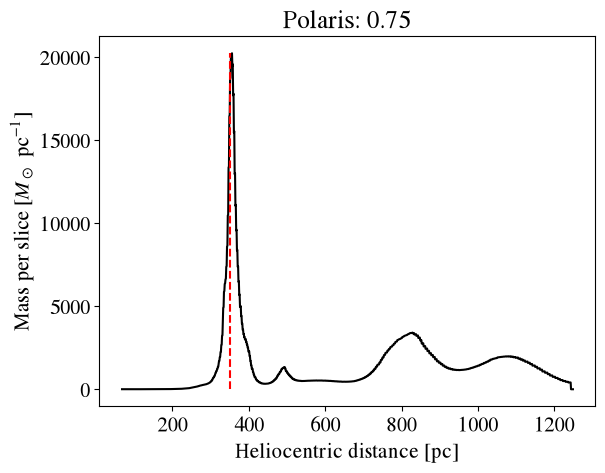

9.033961


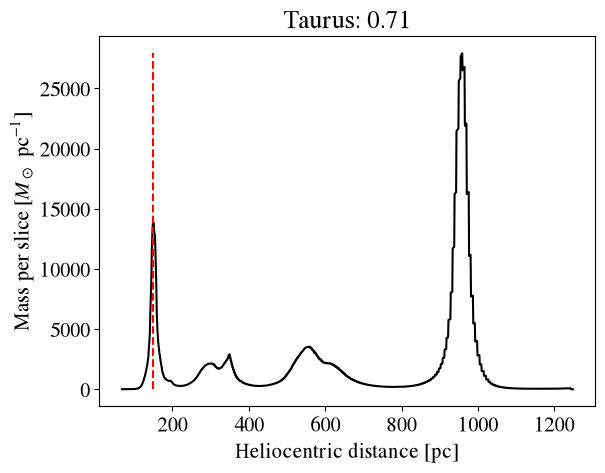

[([<matplotlib.lines.Line2D at 0x1320025a0>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'California: 0.37'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x132043da0>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Camelopardalis: 0.53'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x1320b34a0>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Coalsack: 0.7'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x132132750>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Corona: 0.7'),
  None,
  None),
 ([<matplotlib.lines

In [ ]:
[(
plt.plot(np.arange(cubel.shape[0])+coordsl[4], mass_per_slice.value,
         color='black'), 
# plt.plot(np.arange(cube.shape[0])+coords[4],np.nanmean(cube,axis=(1,2))),

# plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),
plt.vlines(table1.iloc[i]['d_mean(pc)'],0,np.nanmax(mass_per_slice.value),linestyle='--',color='red'),


plt.xlabel('Heliocentric distance [pc]'),
plt.ylabel('Mass per slice [$M_\odot\ \mathrm{pc^{-1}}$]'),
# plt.xlim(table1['d_mean(pc)'].iloc[i]+np.array([-1,1])*300),
plt.title(table1['cloud'].iloc[i]+': '+str(round(np.nansum(cube)/np.nansum(cubel),2))),
# plt.plot(np.nanmean(cube,axis=(1,2)))

print(np.nanstd(np.nanmean(cube,axis=(1,2)))),
# plt.yscale('log'),
plt.show()
) 

for i in range(len(table1))#in_edenhfr #range(26) 
for cube,coords in [get_cloud_info(i,ednhfr_cm3,table1,75)]
for cubel,coordsl in [get_cloud_info(i,ednhfr_cm3,table1,'full')] 
for mass_per_slice in [(np.nansum(cubel,axis=(1,2))*1.36*c.m_p*u.cm**-3 * (0.125*u.deg.to(u.rad)*np.arange(68,1250)*u.pc)**2).to(u.Msun/u.pc)]
]

In [ ]:
# below are log versions of above -- figure out best way to define the cloud

<>:11: SyntaxWarning: invalid escape sequence '\o'
<>:11: SyntaxWarning: invalid escape sequence '\o'
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_2793/4117965967.py:11: SyntaxWarning: invalid escape sequence '\o'
  plt.ylabel('Mass per slice [$M_\odot\ \mathrm{pc^{-1}}$]'),


2.0931032


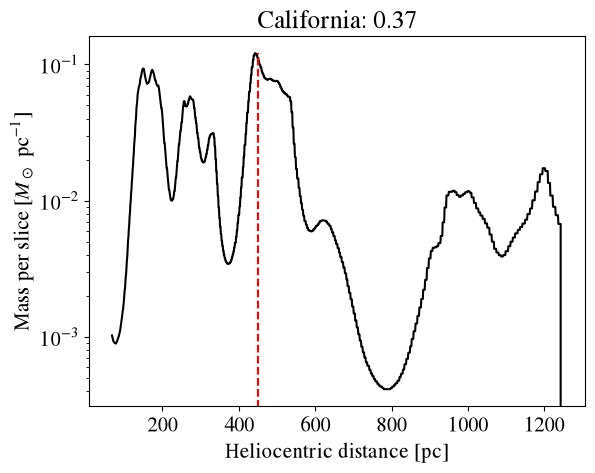

2.550017


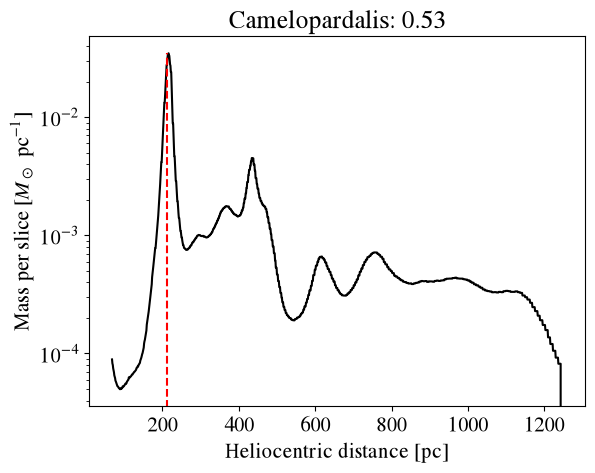

6.277087


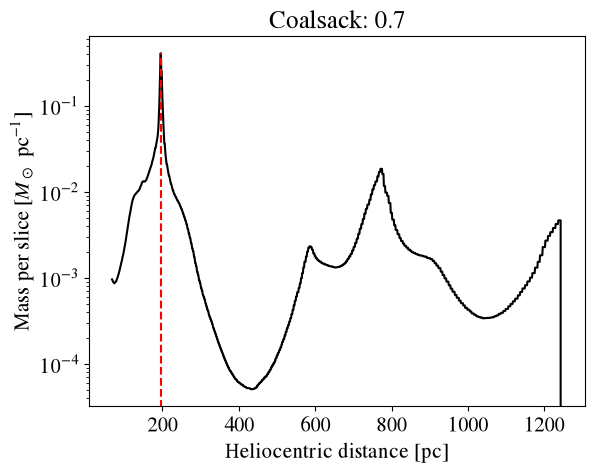

2.3219721


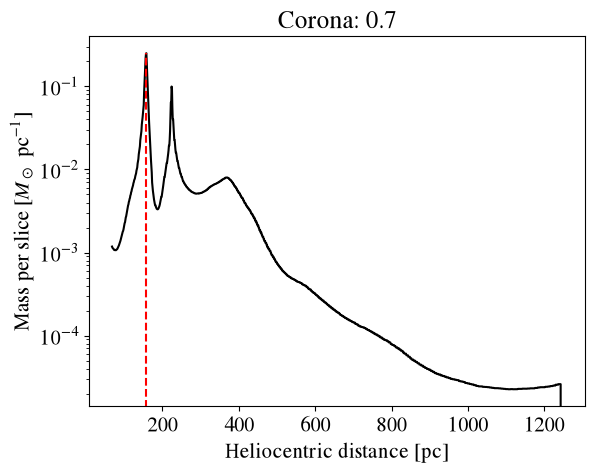

3.415196


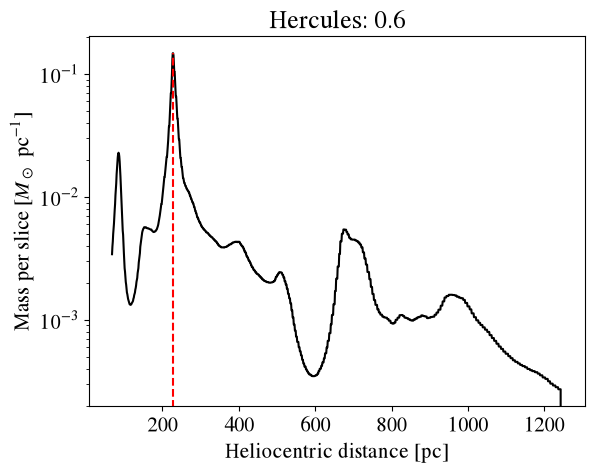

1.9015689


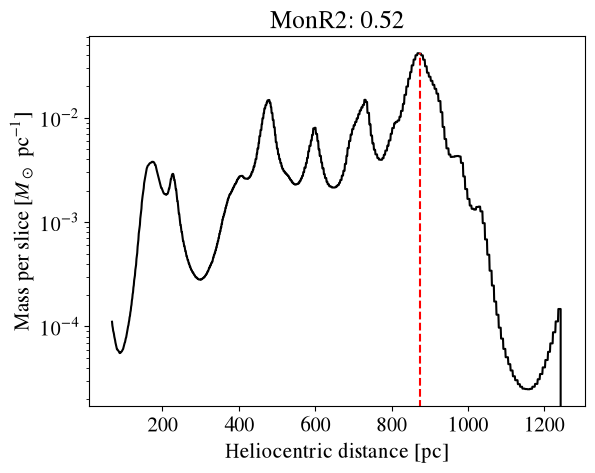

15.848083


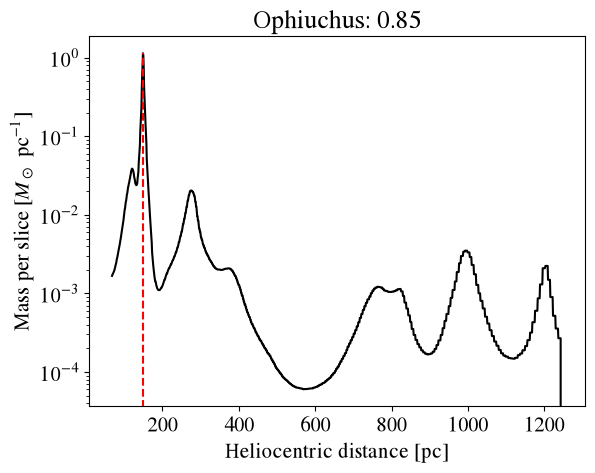

4.9367285


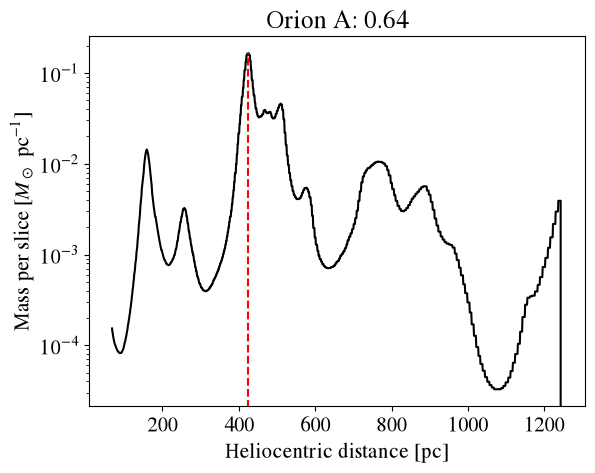

6.8076887


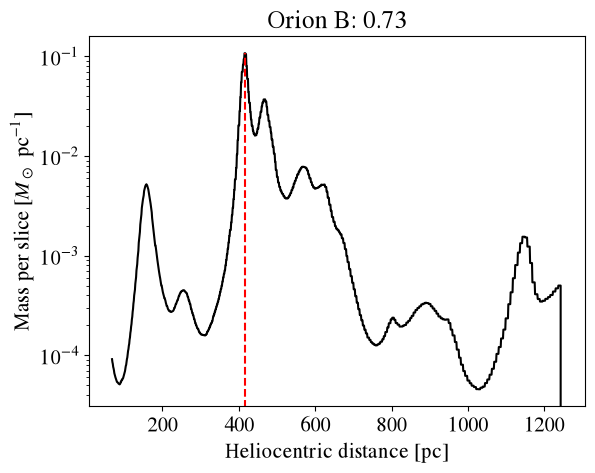

3.968299


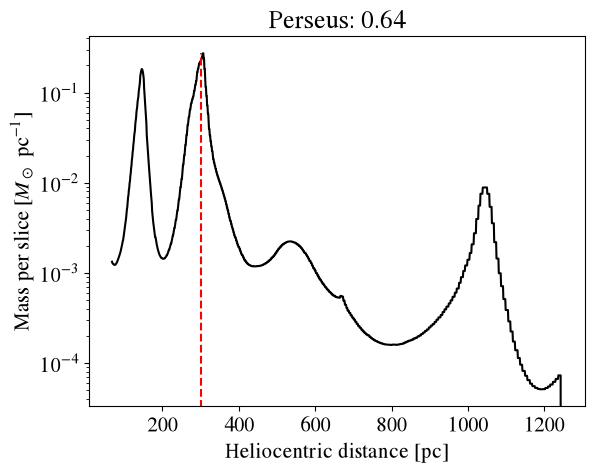

2.772025


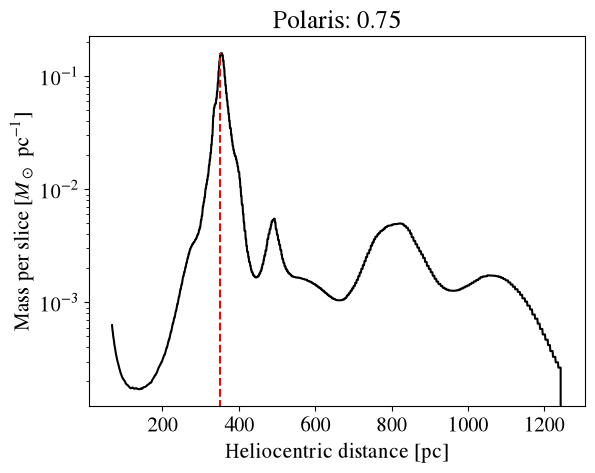

9.033961


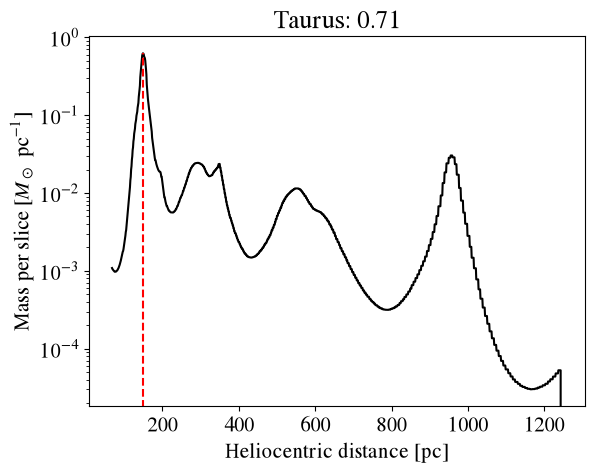

[([<matplotlib.lines.Line2D at 0x132a7f8f0>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'California: 0.37'),
  None,
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x132b9ed20>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Camelopardalis: 0.53'),
  None,
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x1322ec470>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Coalsack: 0.7'),
  None,
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x130a5e600>],
  Text(0.5, 30.83333333333333, 'Heliocentric distance [pc]'),
  Text(34.20833333333334, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  Text(0.5, 1.0, 'Corona: 0.7'),
  None,
  Non

In [107]:
[(
plt.plot(np.arange(cubel.shape[0])+coordsl[4], mass_per_slice.value,
         color='black'), 
# plt.plot(np.arange(cube.shape[0])+coords[4],np.nanmean(cube,axis=(1,2))),

# plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),
plt.vlines(table1.iloc[i]['d_mean(pc)'],0,np.nanmax(mass_per_slice.value),linestyle='--',color='red'),


plt.xlabel('Heliocentric distance [pc]'),
plt.ylabel('Mass per slice [$M_\odot\ \mathrm{pc^{-1}}$]'),
# plt.xlim(table1['d_mean(pc)'].iloc[i]+np.array([-1,1])*300),
plt.title(table1['cloud'].iloc[i]+': '+str(round(np.nansum(cube)/np.nansum(cubel),2))),
# plt.plot(np.nanmean(cube,axis=(1,2)))

print(np.nanstd(np.nanmean(cube,axis=(1,2)))),
plt.yscale('log'),

plt.show()
) 

for i in range(len(table1))#in_edenhfr #range(26) 
for cube,coords in [get_cloud_info(i,ednhfr_cm3,table1,75)]
for cubel,coordsl in [get_cloud_info(i,ednhfr_cm3,table1,'full')] 
for mass_per_slice in [(np.nansum(cubel,axis=(1,2))*1.36*c.m_p*u.cm**-3 * (u.deg.to(u.rad)*u.pc)**2).to(u.Msun/u.pc)]
]

In [41]:
drs = np.nanstd(table1.to_numpy()[:,1:3].astype('float'),axis=1)*u.deg.to(u.rad)*table1['d_mean(pc)']

In [ ]:
# put the spectra <--- into the spax below, and label dmean in a diff color, then 
# show the vlines for what distance ranges is each color

In [139]:
longcubes = [get_cloud_info(i,ednhfr_cm3,table1,'full')[0] 
             for i in range(12)]

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_2793/1553166095.py:1: RuntimeWarning: Mean of empty slice
  [plt.plot(np.nanmean(cube,axis=(1,2))) for cube in longcubes]


[[<matplotlib.lines.Line2D at 0x1391962a0>],

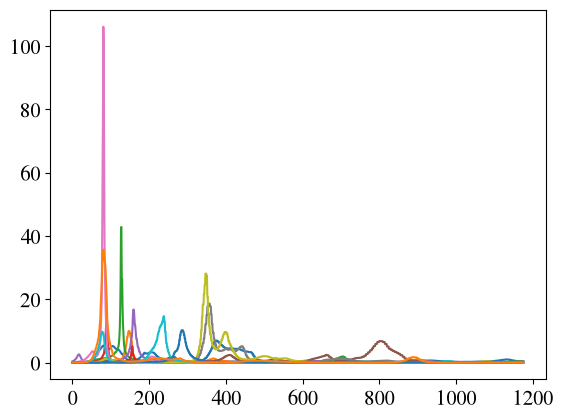

In [143]:
[plt.plot(np.nanmean(cube,axis=(1,2))) for cube in longcubes]

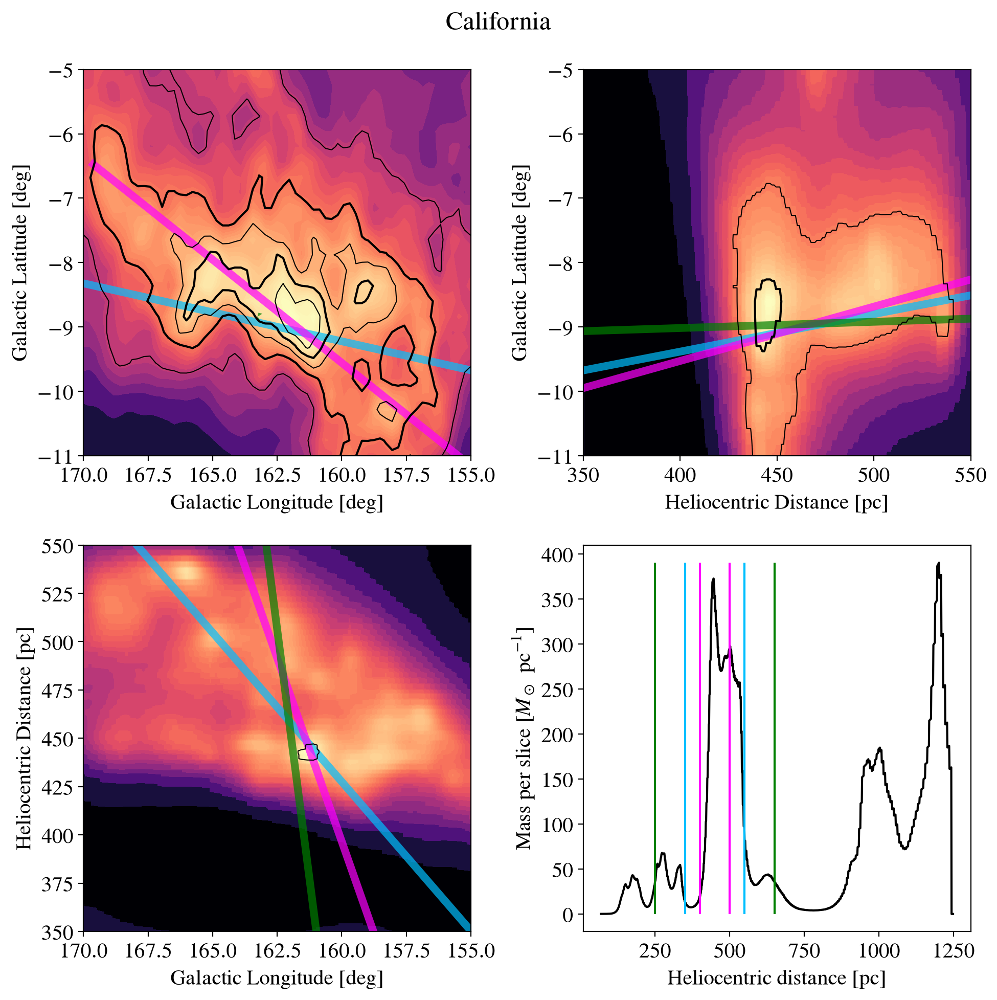

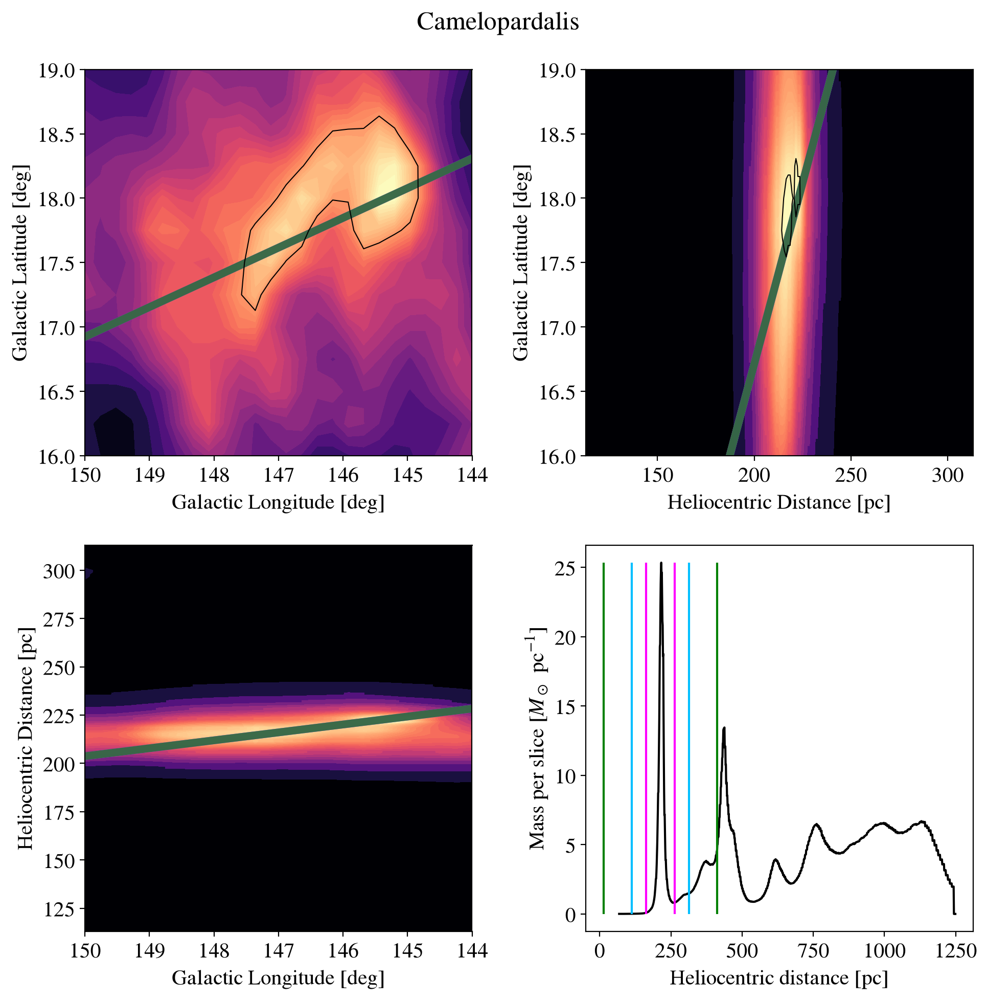

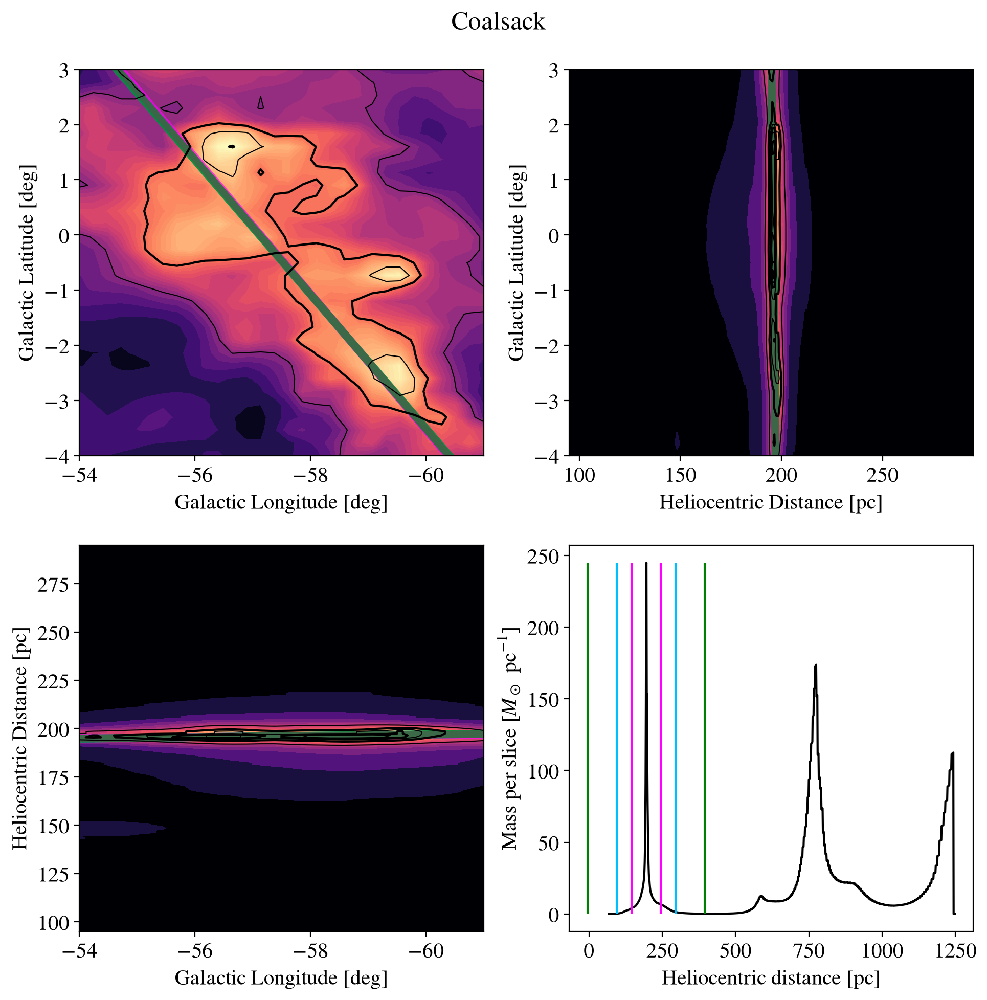

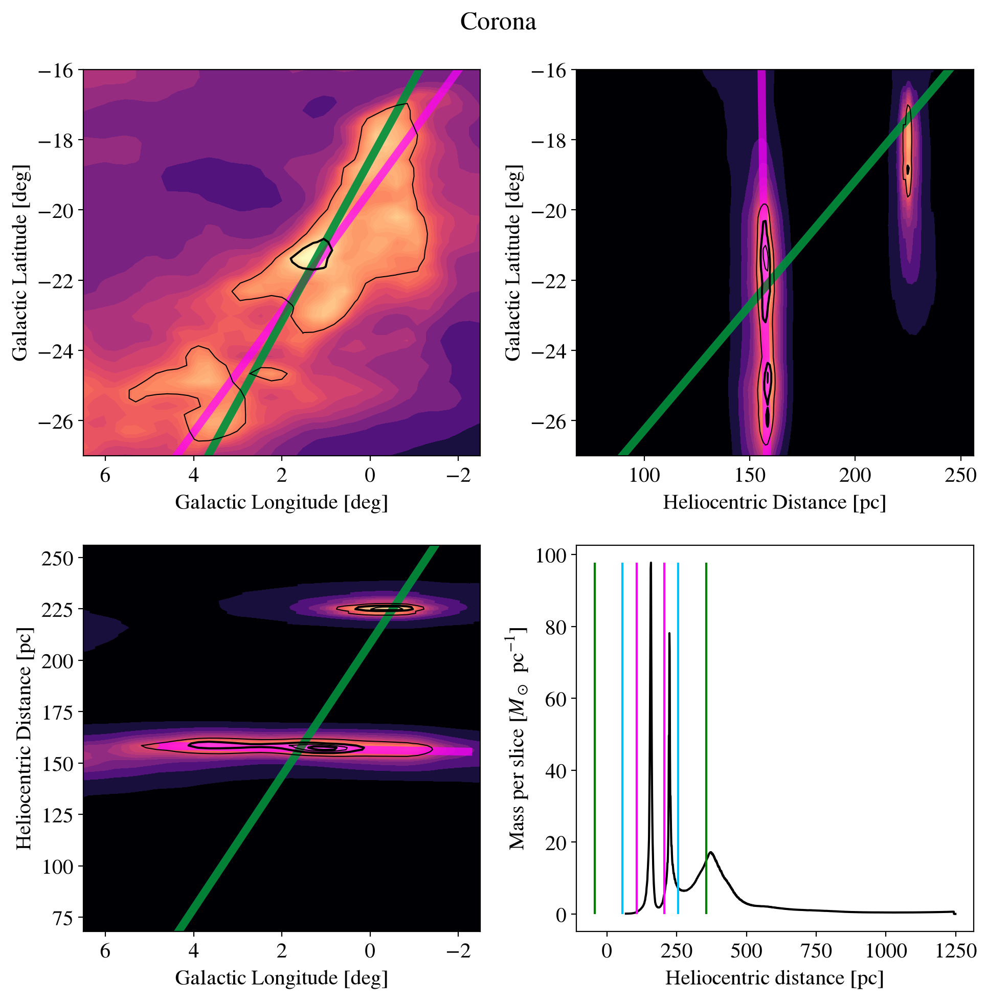

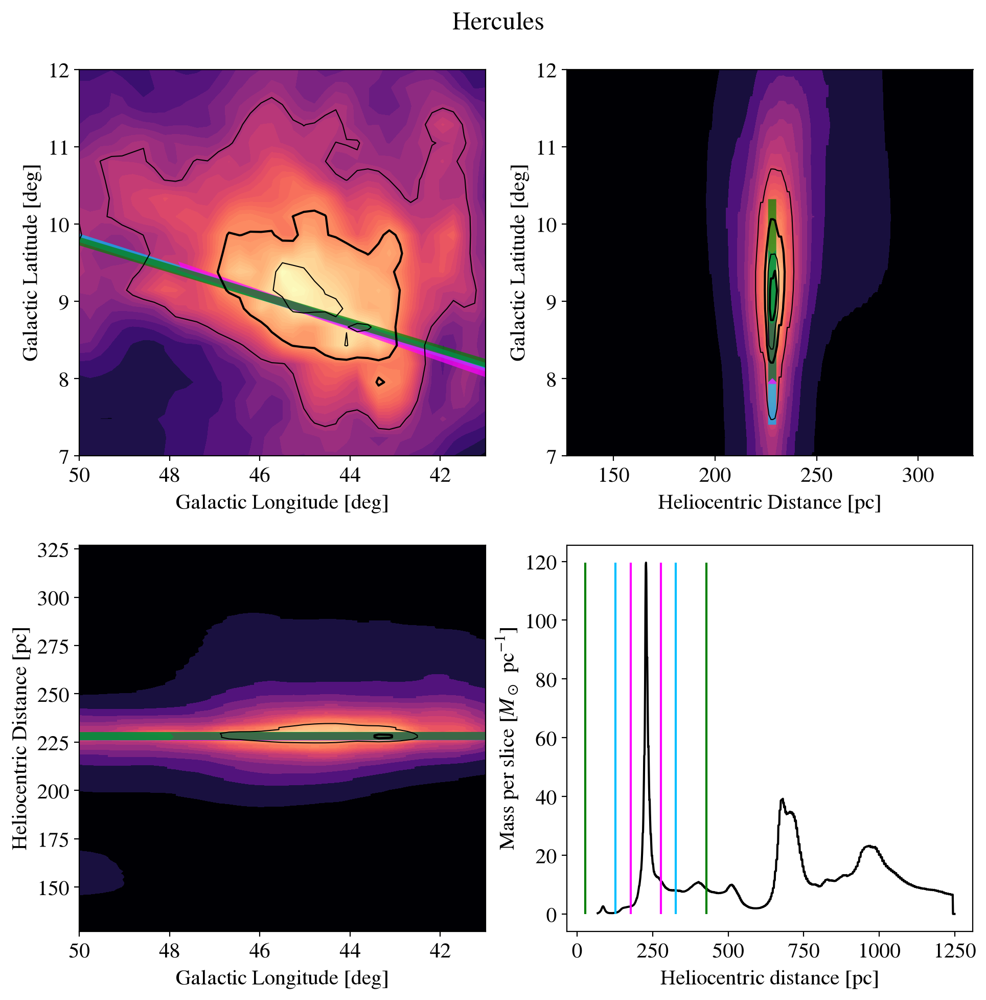

...

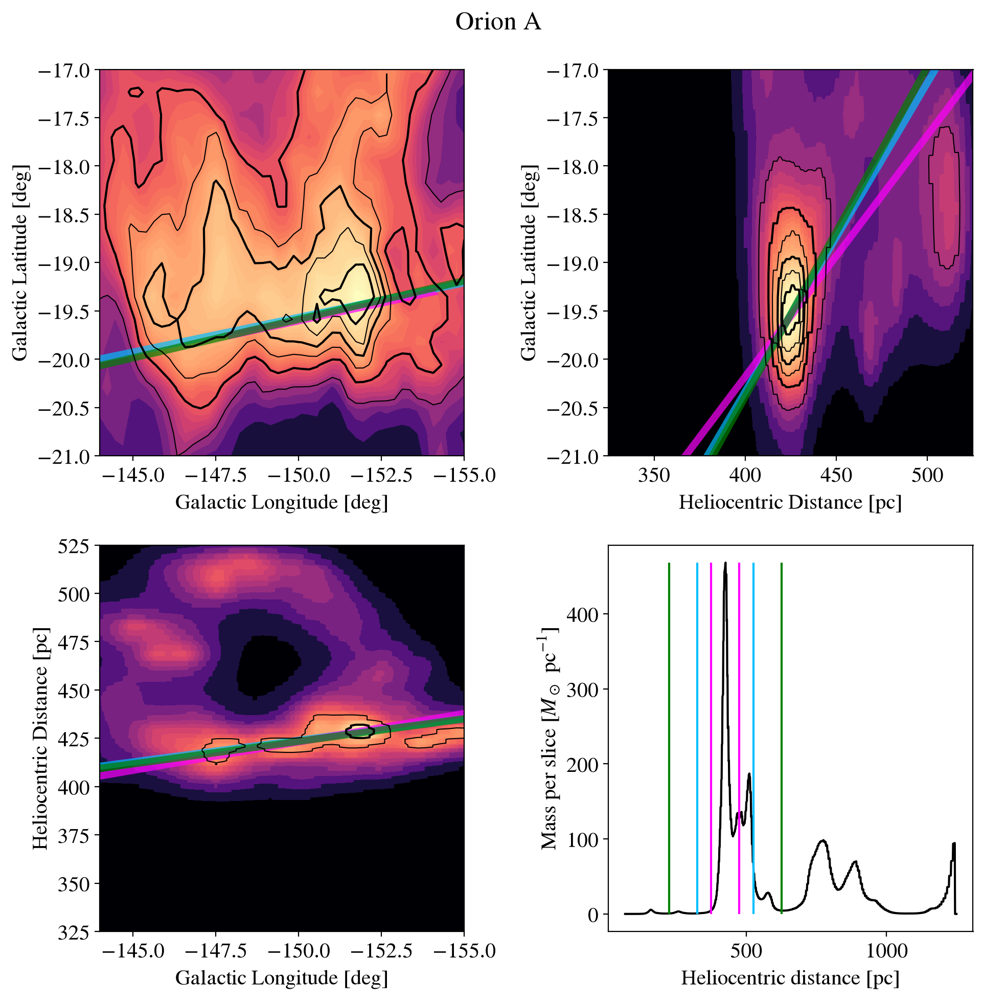

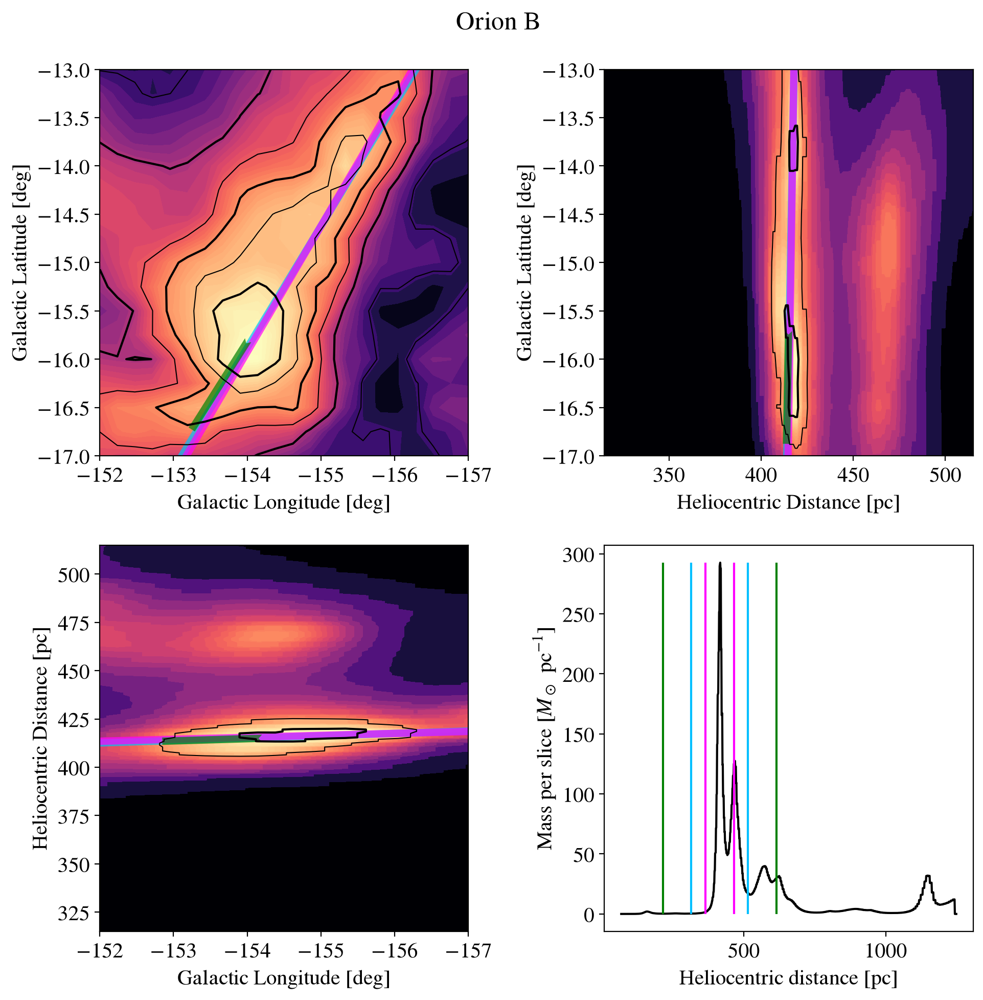

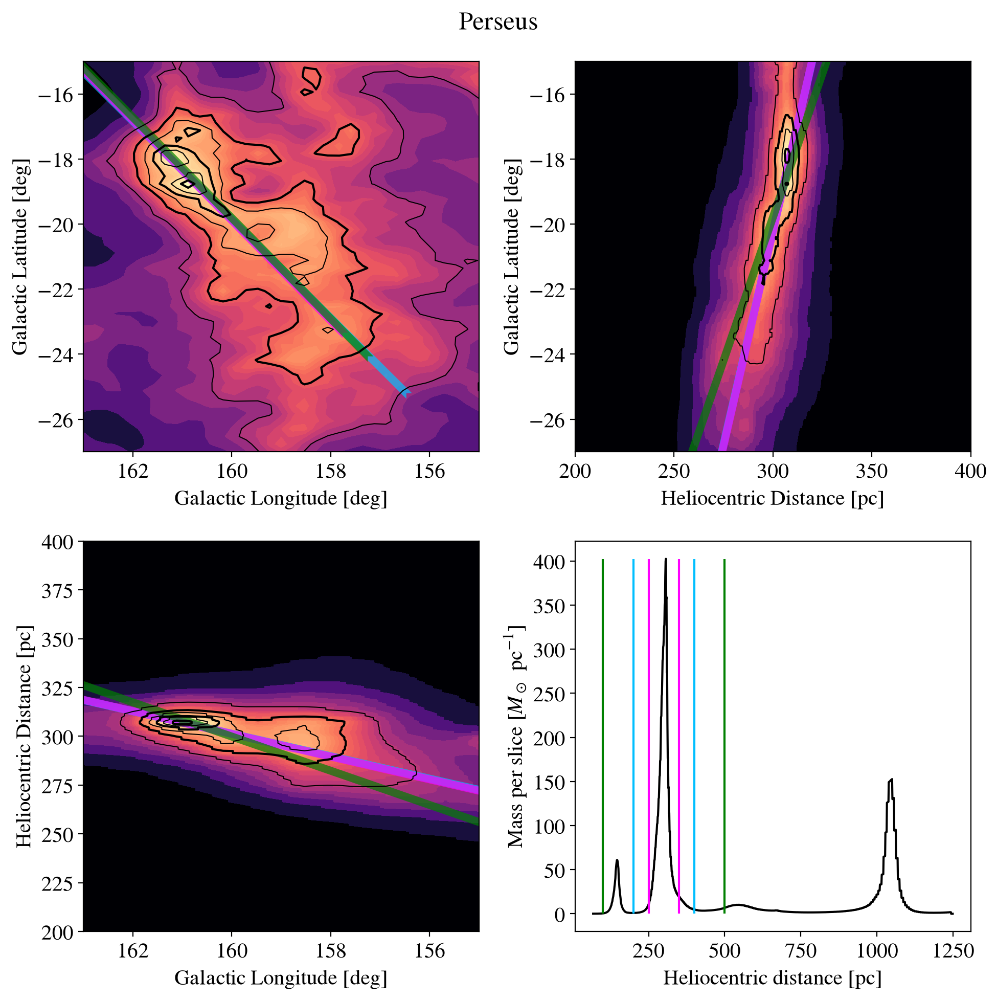

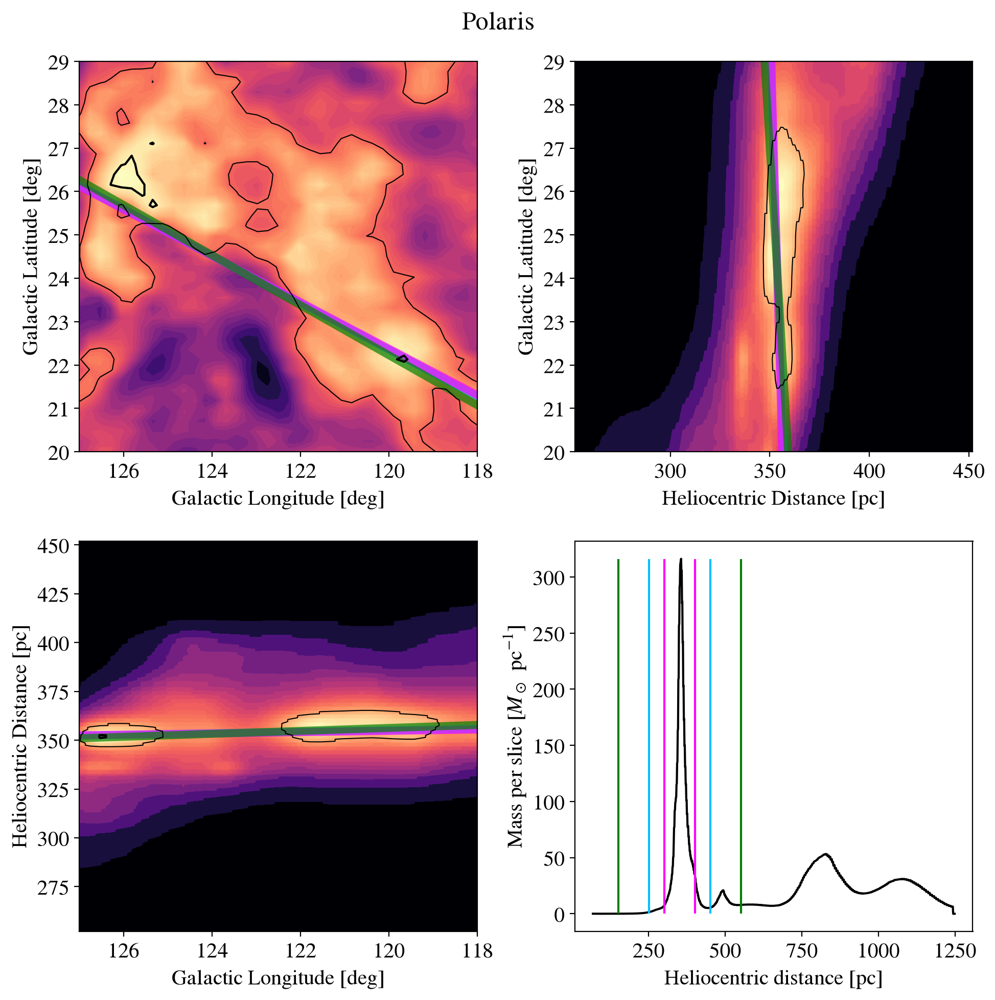

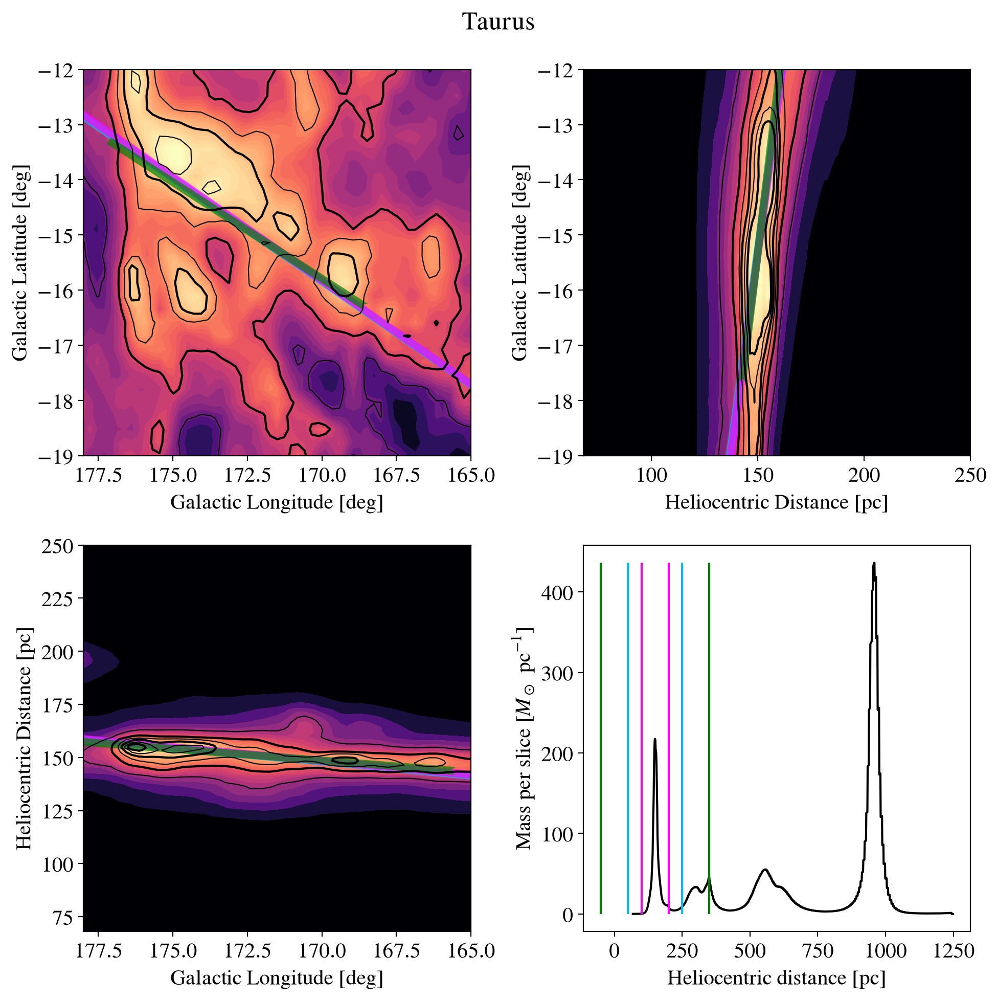

[((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Heliocentric distance [pc]', ylabel='Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'>),
  Text(0.5, 61.66666666666666, 'Heliocentric distance [pc]'),
  Text(1047.1666666666667, 0.5, 'Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'),
  None,
  [(<matplotlib.collections.LineCollection at 0x14192de20>, None),
   (<matplotlib.collections.LineCollection at 0x141b10fb0>, None)],
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Heliocentric distance [pc]', ylabel='Mass per slice [$M_\\odot\\ \\mathrm{pc^{-1}}$]'>)

In [157]:
[(
    
axs,

axs[-1].plot(np.arange(1182)+68,mass_per_slice.value,color='black'),
axs[-1].set_xlabel('Heliocentric distance [pc]'),
axs[-1].set_ylabel(r'Mass per slice [$M_\odot\ \mathrm{pc^{-1}}$]'),
axs[-1].vlines(table1.iloc[i]['d_mean(pc)']+np.array([-1,1])*100,
               0,np.nanmax(mass_per_slice.value),color='deepskyblue'),

plot_spine(axs,dict_['spine'],scolor='deepskyblue'),
[(
axs[-1].vlines(table1.iloc[i]['d_mean(pc)']+np.array([-1,1])*d,
               0,np.nanmax(mass_per_slice.value),color=clr),
plot_spine(axs,dict_['spine'],scolor=clr) 

)
for d,clr in zip([50,200],['magenta','green',]) #zip([3*r,2*r,r],['red','orange','green',])
for dict_ in [ha(i,ednhfr_cm3,table1,d)]
],
     
plt.show())
    
for i in range(12)
for dict_ in [ha(i,ednhfr_cm3,table1,100)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             table1.iloc[i]['cloud'],
                            )]
for mass_per_slice in [(np.nansum(longcubes[i],axis=(1,2))*1.36*c.m_p*u.cm**-3 * (0.125*u.deg.to(u.rad)*np.arange(68,1250)*u.pc)**2).to(u.Msun/u.pc)]

]

In [ ]:
# fig 3: about the distance ranges
# fig 4: spines overlaid on surface density maps
# fig 5: rho vs r (perp and parl) profiles
# fig 6: relationships between r0 rho0 and alpha
# fig 7: M vs cloud / spine properties
# fig 8: tdep vs cloud / spine properties

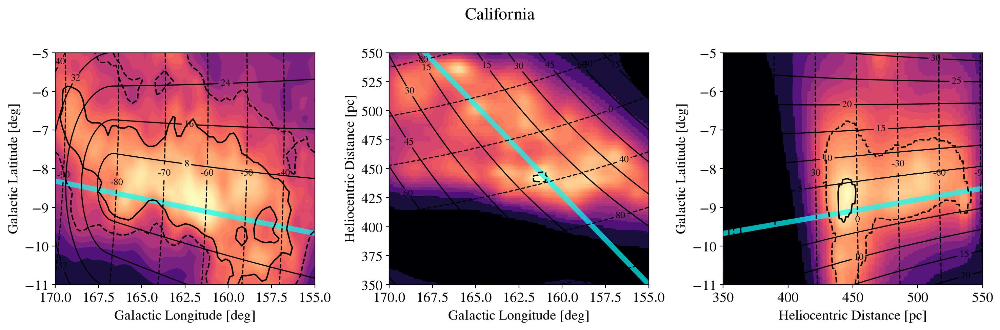

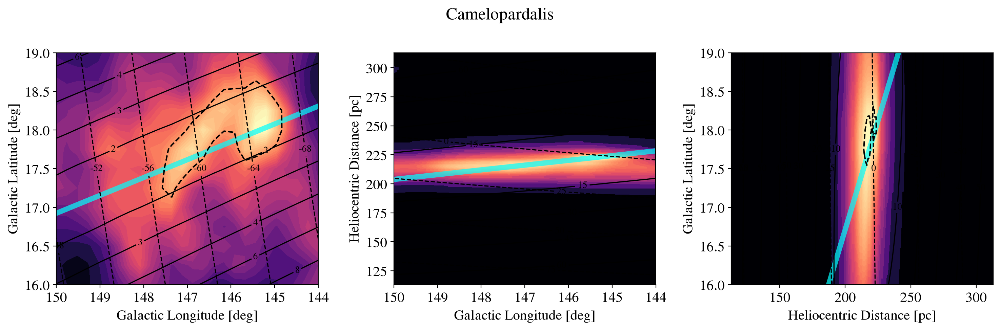

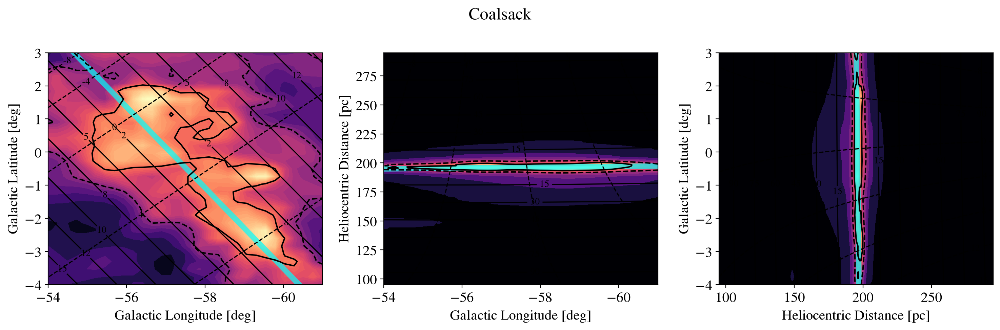

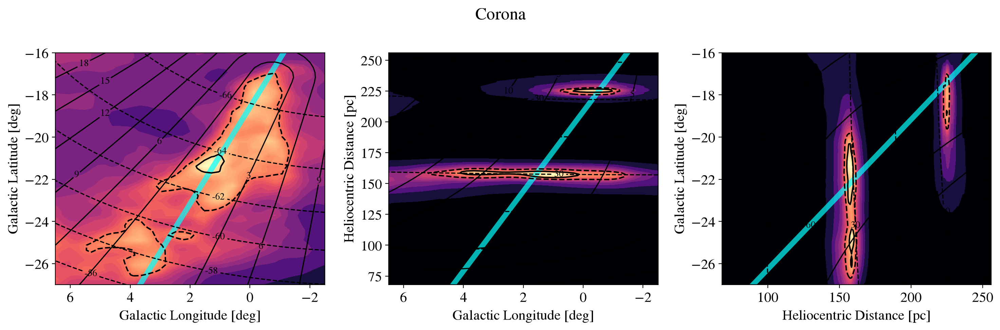

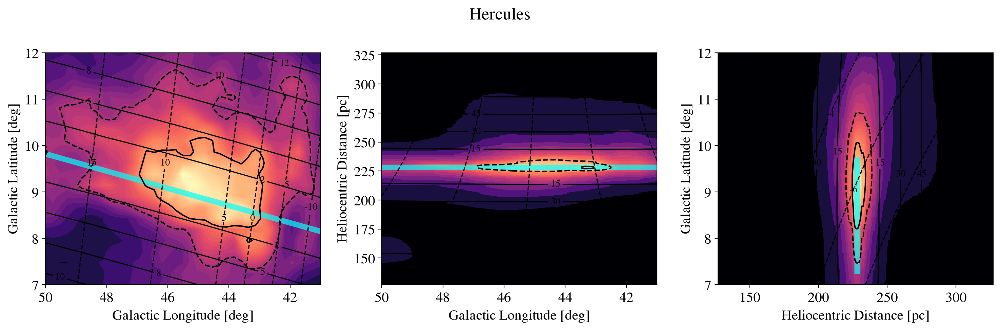

...

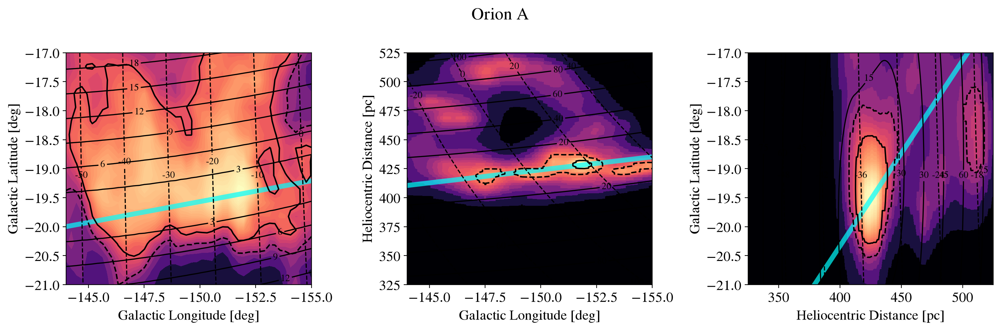

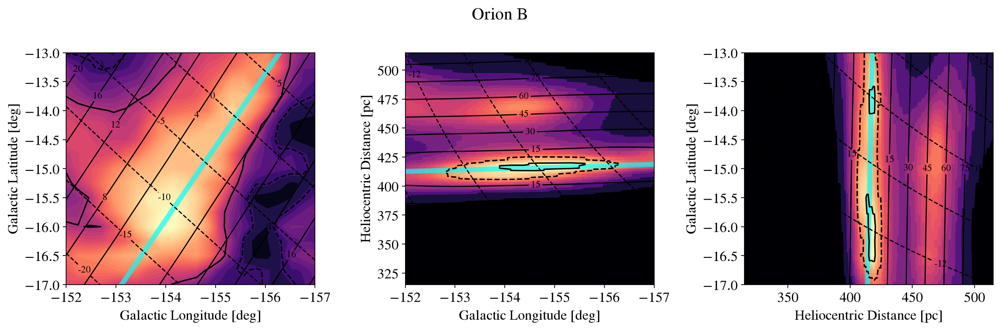

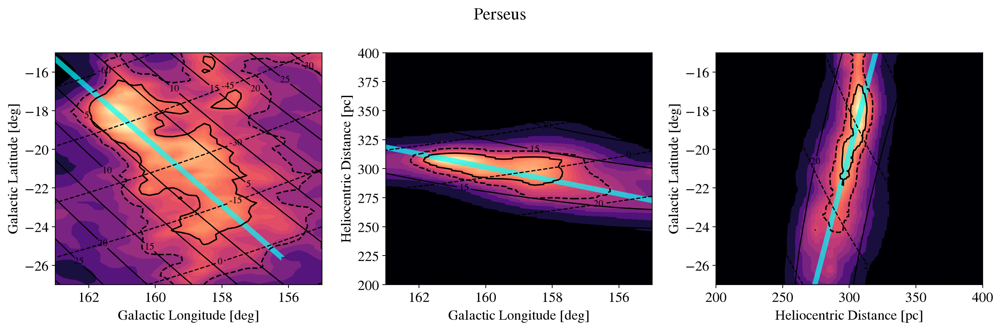

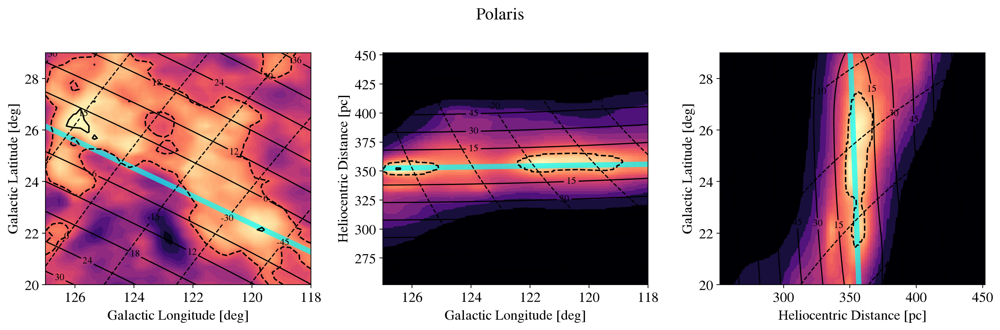

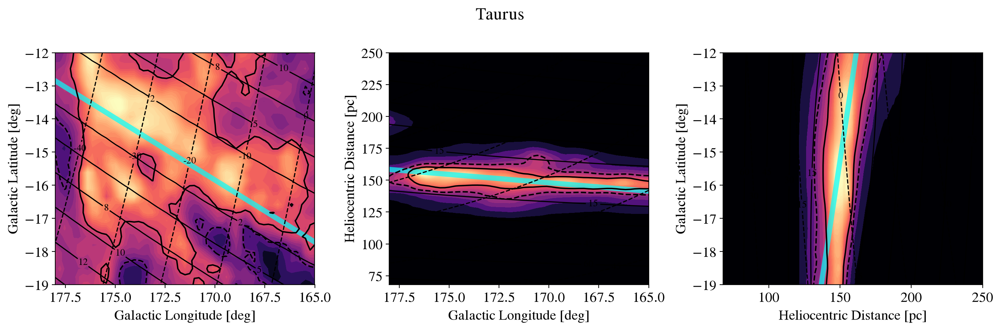

[((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', y

In [51]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),

     
plt.show())
    
for i,r in zip(range(12) ,drs)
for dict_ in [ha(i,ednhfr_cm3,table1,100)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             table1.iloc[i]['cloud'],
                             b_perp=dict_['r_perp'], b_parl=dict_['r_parl'])]

]

# fig 4: density profile along $b_\perp$ and $b_\parallel$

In [ ]:
# just sho 50 100 200 for now
# for later, can work out where to change things to be in terms of r


NameError: name 'cmap_' is not defined

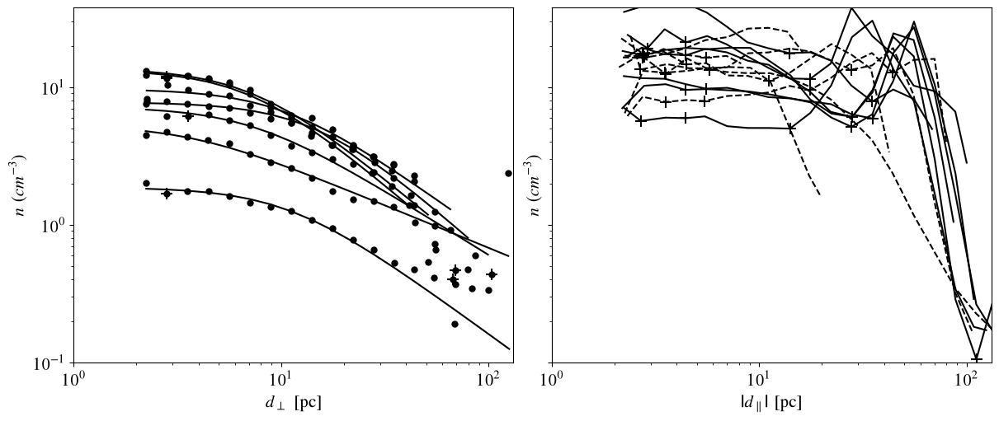

In [165]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,ednhfr_cm3, table1,d,plt_=ax,color='black',lbl=f'{round(d,2)} pc') 
for d in [10,25,50,100,150,300]],

[rho_radial_profiles(i,ednhfr_cm3, table1, d,plt_=ax,color=cmap_(j),lbl=f'{round(d,2)} pc') 
for j,d in enumerate(drs[i]*np.array([0.5,1,2,3,5]))],
    
# ax[0].legend(),
plt.show()
) for i,r in zip(range(12) ,drs)
  for ax,fitpars in [rho_radial_profiles(i,ednhfr_cm3,table1,'by r',color='black',lbl='r')]
]

## show the one along bparallel first -- using a tube of (3? 5? pixels)
## then say from that we get the ends of the spine 

## then the sceond panel is profile along bperp - wehre the distance is calculated along the line
## and beyond the caps yehedu get considered as further away bins of rperp even if theyre on the line

## similar procedure as above to get RT

# save out rho ro alpha ->  bc it is HIGH TIME I STARTED THE PLOTS FOR REAL ANALYSIS

In [ ]:
dds = #come down on a definition

In [ ]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
rho_radial_profiles(i,ednhfr_cm3, dds[i],color='black',lbl=f'{round(dds[i],2)} pc'),
# plt.save_fig('../figures/b_perp_parl'),
# ax[0].legend(),
plt.show()
) for i,r in zip([0],drs[:1])
]

NameError: name 'dds' is not defined

In [ ]:
def record_spine_props(i,source_array,drange,n_jobs=-1):
    cloud_dict = ha(i, source_array, drange, n_jobs=n_jobs)
    save_out = #what is the 

In [ ]:
record_spine_props(0,ednhfr_cm3,100)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,1)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,2)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,3)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,4)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,8)

In [ ]:
pta, veca, dperp, dparl, L1da = get_spine(i, source_array, drange, n_jobs=n_jobs)

In [ ]:
table2 = pd.read_csv('../figures/distance_peaks_by_claude.csv')

In [ ]:
table2

,cloud,b1_pc,b2_pc,b3_pc,b4_pc,b5_pc,b6_pc,b7_pc,b8_pc,b9_pc,b10_pc
0,Aquila_South,183.8,300,,,,,,,,
1,Ophiuchus,129.9,175.4,400,,,,,,,
2,Taurus,176.8,220,346.6,,,,,,,
3,Corona_Australis,74.3,183.8,354.4,,,,,,,
4,Lupus,122.1,160,220,,,,,,,
5,Pipe,176.8,,,,,,,,,
6,Chamaeleon,202.0,,,,,,,,,
7,Coalsack,421.7,,,,,,,,,
8,Hercules,121.2,342.7,523.4,790.7,,,,,,
9,LBN917,84.8,220.2,319.2,,,,,,,


# fig 5: pdfs of the volume density / distance from the spine (varying the distance ranges?)

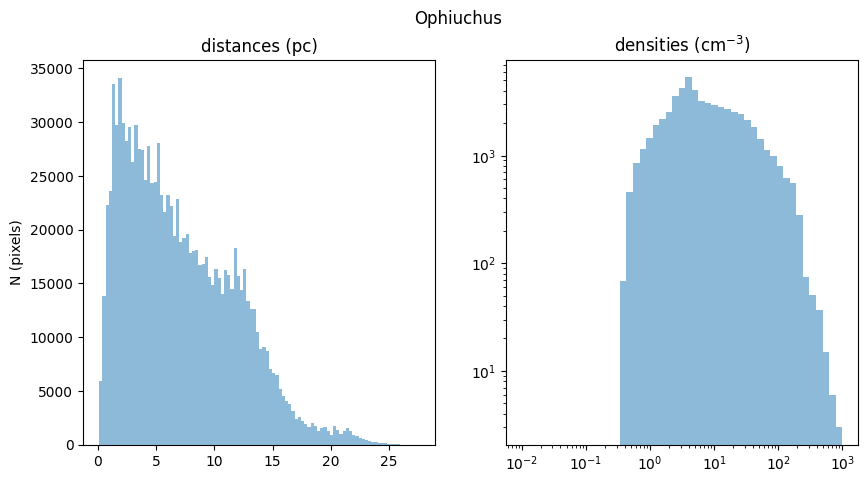

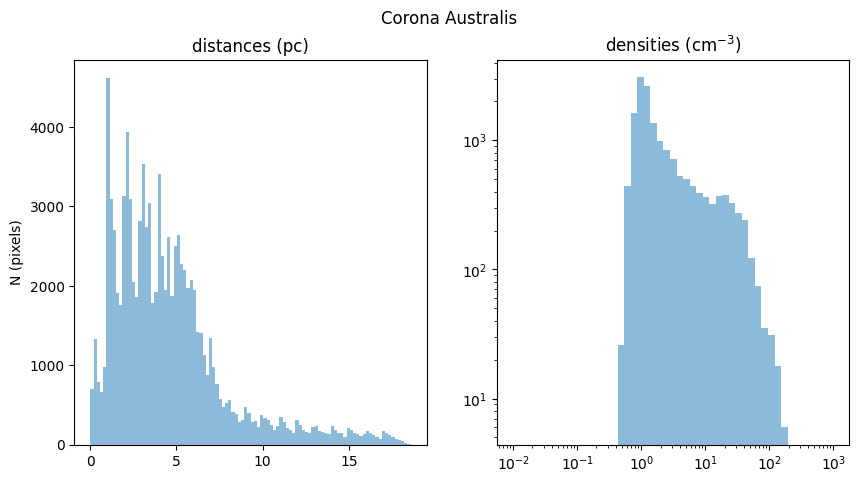

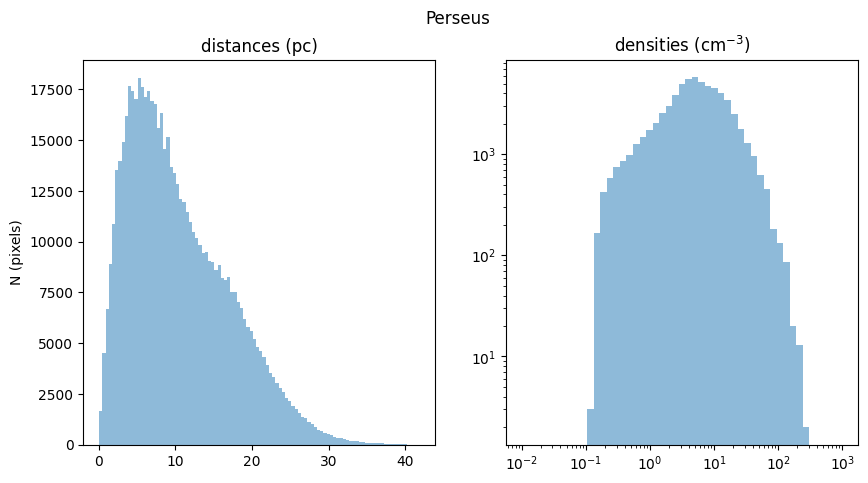

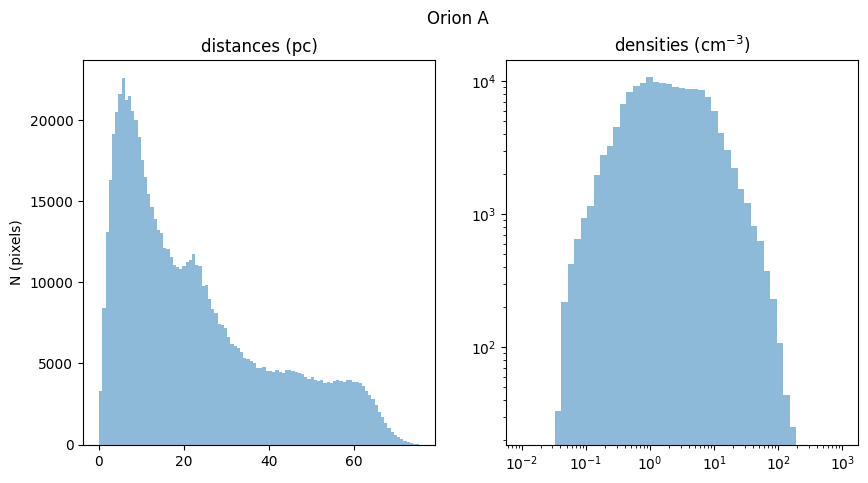

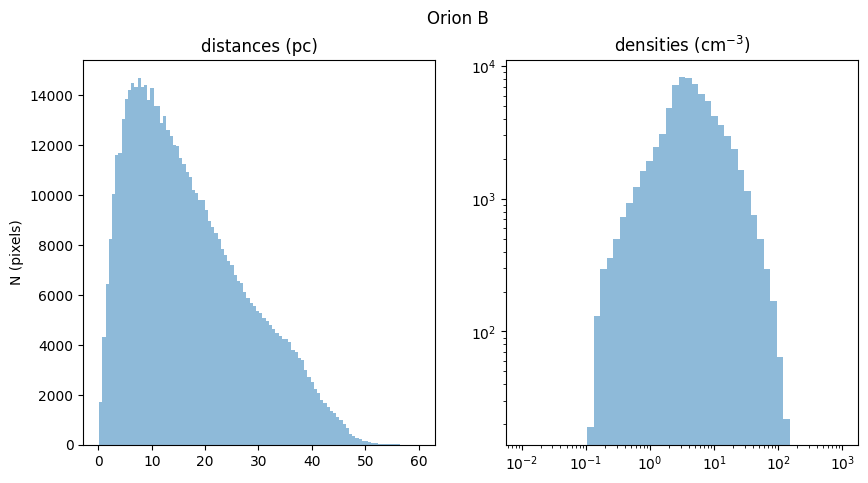

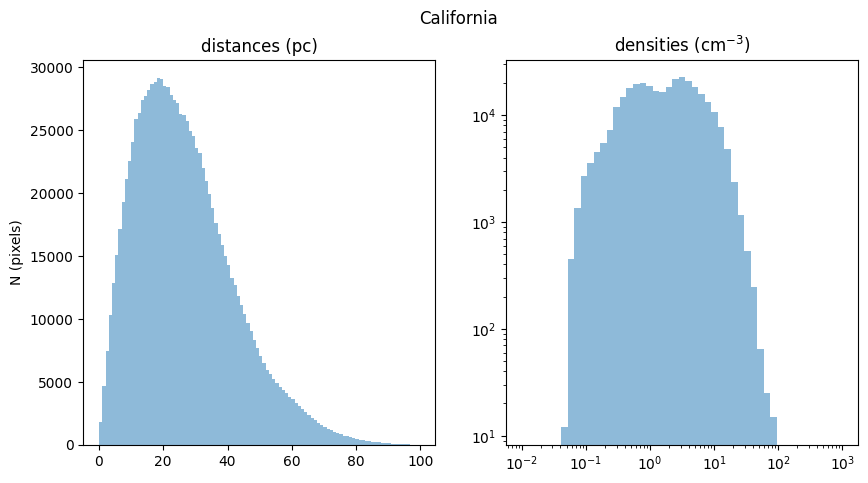

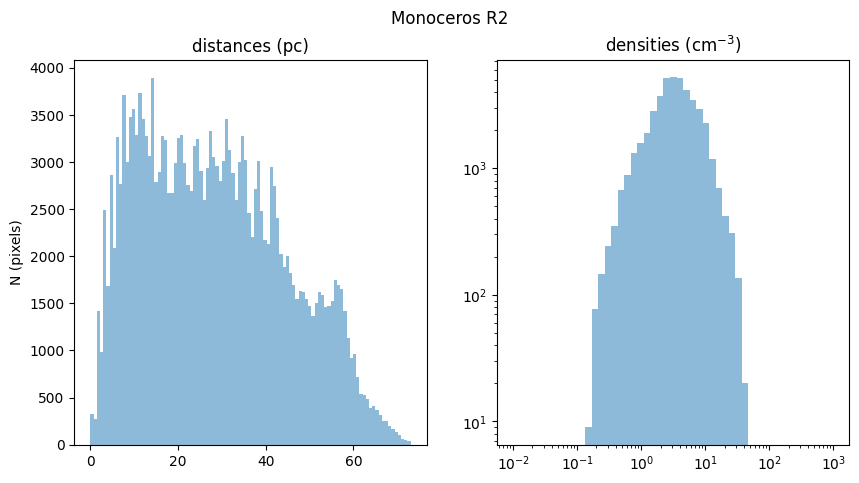

[None, None, None, None, None, None, None]

In [ ]:
[histogram(i,) for i,r in zip(og_if_clouds,lewis_rs)]